<a href="https://colab.research.google.com/github/asegura4488/MecanicaClasica/blob/main/Pista.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

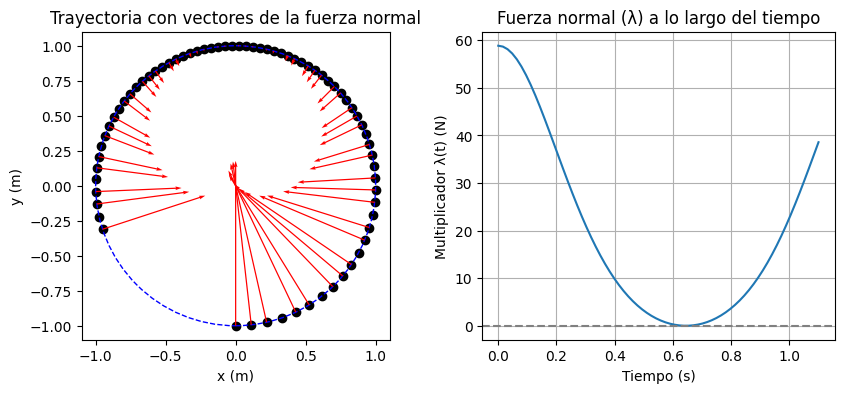

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint

# Parámetros físicos
g = 9.81     # gravedad (m/s^2)
R = 1.0      # radio de la pista (m)
m = 1.0      # masa de la partícula (kg)

# Condiciones iniciales (parte inferior del círculo)
theta0 = -np.pi/2     # ángulo inicial
omega0 = 1*np.sqrt(5*g/R)
#omega0 = 0.1
# Velocidad angular critica
#omega0 = np.sqrt(5*g/R)     # velocidad angular inicial (menor que la crítica)
y0 = [theta0, omega0]

# Ecuaciones del movimiento
def ecuaciones(y, t, g, R):
    theta, omega = y
    dtheta_dt = omega
    domega_dt = -(g / R) * np.cos(theta)
    return [dtheta_dt, domega_dt]

# Tiempo de integración
t = np.linspace(0, 1.1, 70)

# Resolver con odeint
sol = odeint(ecuaciones, y0, t, args=(g, R))
theta = sol[:, 0]
omega = sol[:, 1]

# Calcular lambda(t)
lambda_vals = (m / (2 * R)) * (R * omega**2 - g * np.sin(theta)) * (2*R) # Debido al dos del multiplicador

# Coordenadas cartesianas
x = R * np.cos(theta)
y = R * np.sin(theta)

# --- Dibujar trayectoria con vectores de fuerza normal ---

# Selección de puntos para mostrar vectores (por claridad)
num_arrows = 50
indices = np.linspace(0, len(t) - 1, num_arrows, dtype=int)

# Componentes de la fuerza normal: -λ * (x̂, ŷ)
normals_x = -lambda_vals[indices] * x[indices] / R
normals_y = -lambda_vals[indices] * y[indices] / R

# Escalado visual
scale = 0.02


fig = plt.figure(figsize=(10,4))
ax = fig.add_subplot(121)
ax.scatter(x, y, color='k' ,label="Trayectoria")
circle = plt.Circle((0, 0), R, color='b', fill=False, linestyle='--', label="Pista circular")
ax.add_patch(circle)

ax1 = fig.add_subplot(122)
ax1.plot(t, lambda_vals, label="λ(t)")
ax1.axhline(0, color='gray', linestyle='--')
ax1.set_xlabel("Tiempo (s)")
ax1.set_ylabel("Multiplicador λ(t) (N)")
ax1.set_title("Fuerza normal (λ) a lo largo del tiempo")
ax1.grid(True)

# Vectores normales (fuerza de restricción)
ax.quiver(
    x[indices], y[indices],
    normals_x, normals_y,
    angles='xy', scale_units='xy', scale=1/scale,
    color='red', width=0.004, label='Fuerza normal (−λ ∇f)'
)

ax.set_aspect('equal')
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Trayectoria con vectores de la fuerza normal")
#ax.legend()
plt.show()

In [12]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import odeint
from matplotlib.animation import FuncAnimation
from IPython.display import HTML

g = 9.81
R = 1.0
m = 1.0

theta0 = -np.pi/2
omega0 = 1*np.sqrt(5*g/R)
y0 = [theta0, omega0]

def ecuaciones(y, t, g, R):
    theta, omega = y
    dtheta_dt = omega
    domega_dt = -(g/R)*np.cos(theta)
    return [dtheta_dt, domega_dt]

t = np.linspace(0, 1.1, 150)

sol = odeint(ecuaciones, y0, t, args=(g, R))
theta = sol[:, 0]
omega = sol[:, 1]

lambda_vals = m*(R*omega**2 - g*np.sin(theta))

x = R*np.cos(theta)
y = R*np.sin(theta)

fig, (ax, ax1) = plt.subplots(1, 2, figsize=(11, 4))

ax.set_aspect("equal")
ax.set_xlim(-1.7*R, 1.7*R)
ax.set_ylim(-1.7*R, 1.7*R)
ax.set_xlabel("x (m)")
ax.set_ylabel("y (m)")
ax.set_title("Partícula, normal y peso")

circle = plt.Circle((0, 0), R, color="b", fill=False, linestyle="--")
ax.add_patch(circle)

particle, = ax.plot([], [], "ko", markersize=8)
trail, = ax.plot([], [], "k-", alpha=0.4)

normal_arrow = ax.annotate(
    "",
    xy=(0, 0),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle="->", color="red", lw=2)
)

peso_arrow = ax.annotate(
    "",
    xy=(0, 0),
    xytext=(0, 0),
    arrowprops=dict(arrowstyle="->", color="green", lw=2)
)

ax.text(-1.55, 1.45, "Rojo: normal", color="red")
ax.text(-1.55, 1.25, "Verde: peso", color="green")

ax1.set_xlim(t[0], t[-1])
ax1.set_ylim(1.1*np.min(lambda_vals), 1.1*np.max(lambda_vals))
ax1.set_xlabel("Tiempo (s)")
ax1.set_ylabel(r"$\lambda(t)$")
ax1.set_title("Multiplicador de Lagrange")
ax1.grid(True)

ax1.plot(t, lambda_vals, color="gray", alpha=0.4)
point_lambda, = ax1.plot([], [], "ro")
line_lambda, = ax1.plot([], [], "r-")

arrow_scale = 0.35 / np.max(np.abs(lambda_vals))
peso_scale = 0.35 / (m*g)

def init():
    particle.set_data([], [])
    trail.set_data([], [])

    point_lambda.set_data([], [])
    line_lambda.set_data([], [])

    normal_arrow.xy = (0, 0)
    normal_arrow.set_position((0, 0))

    peso_arrow.xy = (0, 0)
    peso_arrow.set_position((0, 0))

    return particle, trail, point_lambda, line_lambda, normal_arrow, peso_arrow

def update(i):
    particle.set_data([x[i]], [y[i]])
    trail.set_data(x[:i+1], y[:i+1])

    # ---------------------
    # Fuerza normal
    # ---------------------
    Fx_N = -lambda_vals[i] * x[i] / R
    Fy_N = -lambda_vals[i] * y[i] / R

    Fx_N_plot = arrow_scale * Fx_N
    Fy_N_plot = arrow_scale * Fy_N

    normal_arrow.xy = (x[i] + Fx_N_plot, y[i] + Fy_N_plot)
    normal_arrow.set_position((x[i], y[i]))

    # ---------------------
    # Peso
    # ---------------------
    Fx_W = 0
    Fy_W = -m*g

    Fx_W_plot = peso_scale * Fx_W
    Fy_W_plot = peso_scale * Fy_W

    peso_arrow.xy = (x[i] + Fx_W_plot, y[i] + Fy_W_plot)
    peso_arrow.set_position((x[i], y[i]))

    point_lambda.set_data([t[i]], [lambda_vals[i]])
    line_lambda.set_data(t[:i+1], lambda_vals[:i+1])

    return particle, trail, point_lambda, line_lambda, normal_arrow, peso_arrow

ani = FuncAnimation(
    fig,
    update,
    frames=len(t),
    init_func=init,
    interval=60,
    blit=False
)

plt.close(fig)

HTML(ani.to_jshtml())